In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv('SP500R2000.csv')
df.head()

,company_name,avg_market_cap_2025_usd,avg_stock_price_2025_usd,is_usa,pct_women_board,is_sp500
0,Company_001,8.780382e+10,79.84,1,57.7,1
1,Company_002,2.179898e+11,82.43,1,48.5,1
2,Company_003,1.996466e+10,100.87,1,18.5,1
3,Company_004,4.685089e+10,153.15,1,33.1,1
4,Company_005,8.700219e+10,229.35,1,25.4,1


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   company_name              500 non-null    object 
 1   avg_market_cap_2025_usd   500 non-null    float64
 2   avg_stock_price_2025_usd  500 non-null    float64
 3   is_usa                    500 non-null    int64  
 4   pct_women_board           500 non-null    float64
 5   is_sp500                  500 non-null    int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 23.6+ KB


In [16]:
df.columns

Index(['company_name', 'avg_market_cap_2025_usd', 'avg_stock_price_2025_usd',
       'is_usa', 'pct_women_board', 'is_sp500'],
      dtype='object')

In [17]:
df['is_usa'].nunique()



2

In [18]:
df['is_sp500'].nunique()

2

In [19]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
company_name,500,500,Company_001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_market_cap_2025_usd,500.0,NaN,NaN,NaN,29662847924.063484,92144038711.079987,179666760.59,991943039.2475,2053146028.93,5787719124.3975,1031139101232.819946
avg_stock_price_2025_usd,500.0,NaN,NaN,NaN,74.83792,98.207393,3.0,23.435,41.2,86.995,1023.74
is_usa,500.0,NaN,NaN,NaN,0.924,0.265264,0.0,1.0,1.0,1.0,1.0
pct_women_board,500.0,NaN,NaN,NaN,30.737,10.74697,0.0,23.925,30.45,37.6,60.0
is_sp500,500.0,NaN,NaN,NaN,0.2,0.400401,0.0,0.0,0.0,0.0,1.0


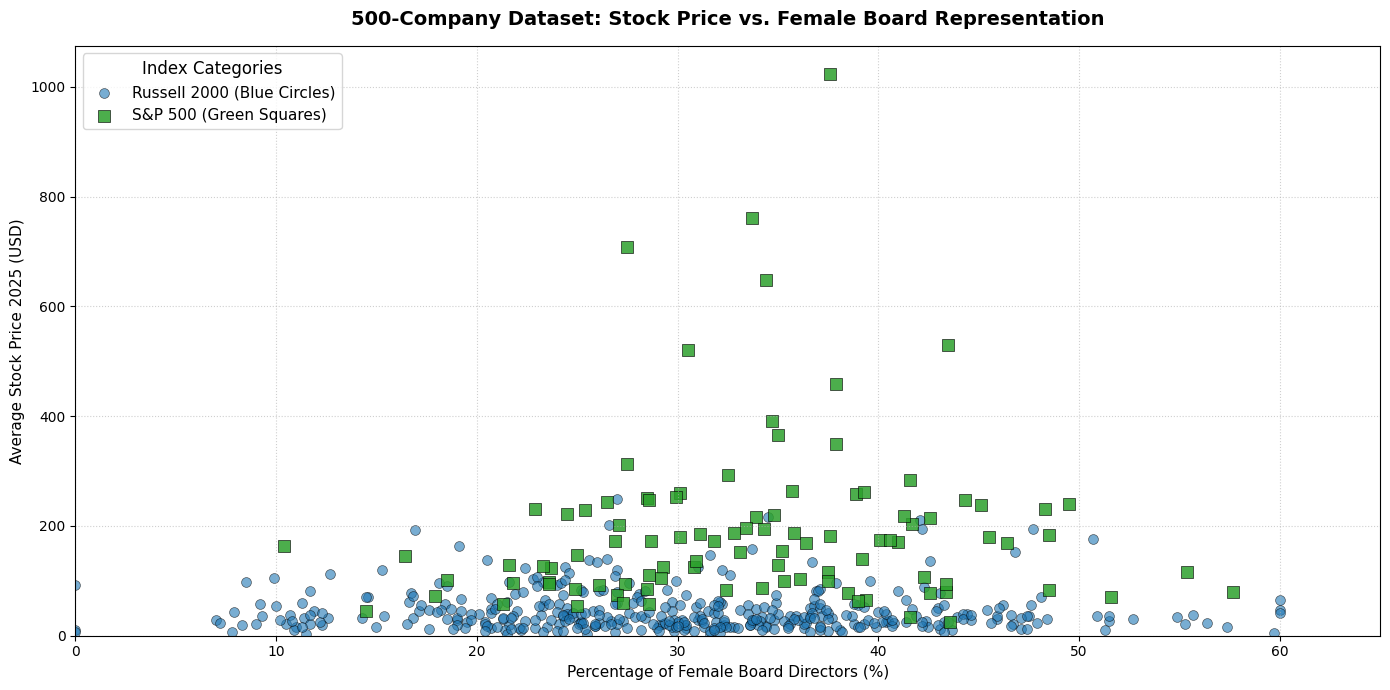

In [20]:
#creating two dataframes for S&P500 and Russell2000
sp500_all = df[df["is_sp500"] == 1].copy()
russell_all = df[df["is_sp500"] == 0].copy()

# plot the avreage stock price in 2025
#vs. percentage of women in the board of directors

plt.figure(figsize=(14, 7))
# for Russel2000
plt.scatter(
    russell_all["pct_women_board"],
    russell_all["avg_stock_price_2025_usd"],
    color='#1f77b4',
    s=50,
    marker='o',
    alpha=0.6,
    edgecolors='k',
    linewidth=0.5,
    label='Russell 2000 (Blue Circles)'
)

# for S&P500
plt.scatter(
    sp500_all["pct_women_board"],
    sp500_all["avg_stock_price_2025_usd"],
    color='#2ca02c',
    s=70,
    marker='s',
    alpha=0.85,
    edgecolors='k',
    linewidth=0.5,
    label='S&P 500 (Green Squares)'
)

plt.xlim(0, 65)
plt.ylim(0, max(df["avg_stock_price_2025_usd"]) * 1.05)


plt.title("500-Company Dataset: Stock Price vs. Female Board Representation", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Percentage of Female Board Directors (%)", fontsize=11)
plt.ylabel("Average Stock Price 2025 (USD)", fontsize=11)


plt.legend(
    title="Index Categories",
    fontsize=11,
    title_fontsize=12,
    frameon=True,
    loc='upper left'
)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_689/3795939196.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(


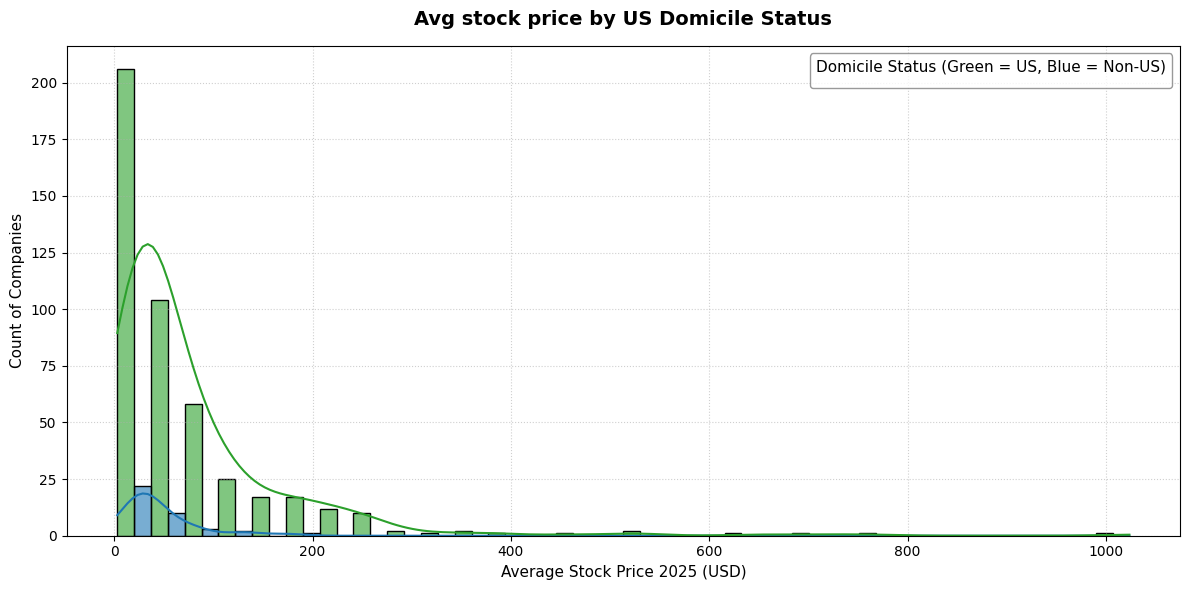

In [23]:
# comparison of avegare market value in 2025
# in the U.S. vs outside the U.S.

df["domicile"] = df["is_usa"].map({1: "U.S.-Domiciled", 0: "Non-U.S. Domiciled"})


plt.figure(figsize=(12, 6))


custom_palette = {
    "U.S.-Domiciled": "#2ca02c",      # Green
    "Non-U.S. Domiciled": "#1f77b4"  # Blue
}


ax = sns.histplot(
    data=df,
    x='avg_stock_price_2025_usd',
    hue='domicile',
    palette=custom_palette,
    multiple='dodge',
    bins=30,
    kde=True,
    alpha=0.6
)


plt.title('Avg stock price by US Domicile Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Stock Price 2025 (USD)', fontsize=11)
plt.ylabel('Count of Companies', fontsize=11)


handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles=handles,
    labels=labels,
    title='Domicile Status (Green = US, Blue = Non-US)',
    fontsize=11,
    title_fontsize=11,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    loc='upper right'
)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_689/217164283.py:30: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(


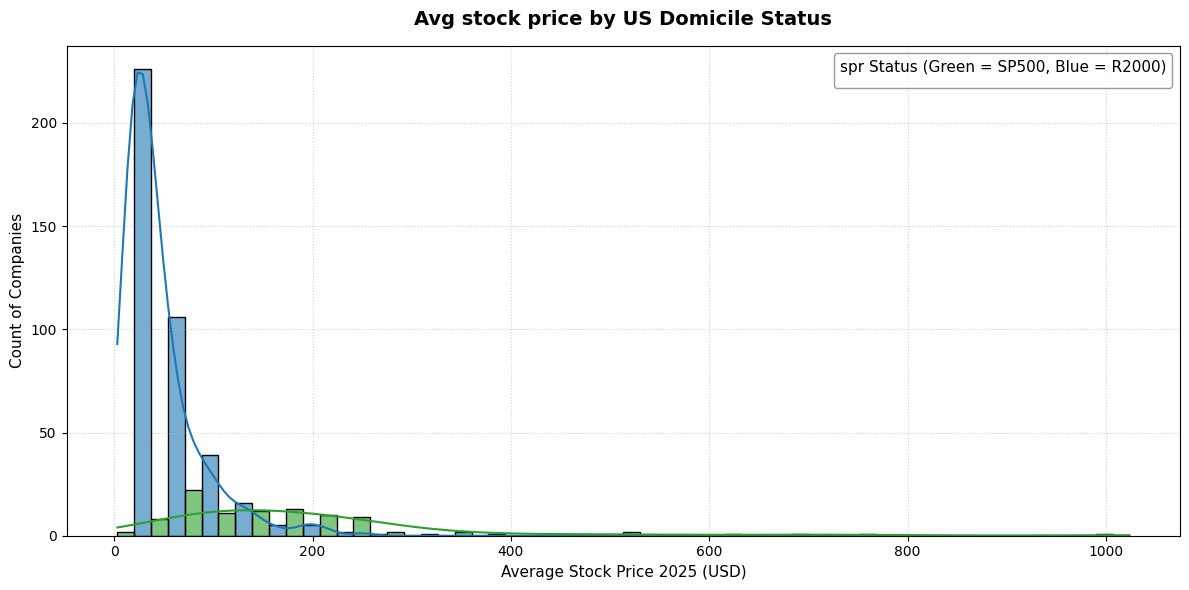

In [24]:
# comparison of avegare market value in 2025 between
# a random sample of S&P500 and a random sample of Rusell2000

df["spr"] = df["is_sp500"].map({1: "SP500", 0: "R2000"})

plt.figure(figsize=(12, 6))

custom_palette = {
    "SP500": "#2ca02c",      # Green
    "R2000": "#1f77b4"  # Blue
}

ax = sns.histplot(
    data=df,
    x='avg_stock_price_2025_usd',
    hue='spr',
    palette=custom_palette,
    multiple='dodge',
    bins=30,
    kde=True,
    alpha=0.6
)


plt.title('Avg stock price by US Domicile Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Average Stock Price 2025 (USD)', fontsize=11)
plt.ylabel('Count of Companies', fontsize=11)

handles, labels = ax.get_legend_handles_labels()
plt.legend(
    handles=handles,
    labels=labels,
    title='spr Status (Green = SP500, Blue = R2000)',
    fontsize=11,
    title_fontsize=11,
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    loc='upper right'
)

plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()